## 1. Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("..") / "data" / "raw"
print(DATA_DIR.resolve(), DATA_DIR.exists())

C:\Users\ibrah\projects\creditflow-intelligence\data\raw True


In [2]:
df = pd.read_csv(DATA_DIR / "application_train.csv")
df.shape

(307511, 122)

In [3]:
dictionary = pd.read_csv(DATA_DIR / "HomeCredit_columns_description.csv", encoding="latin-1")

## 2. Data orientation

In [4]:
from collections import defaultdict

groups = defaultdict(list)
for c in df.columns:
    groups[c.split("_")[0]].append(c)

for prefix, cols in sorted(groups.items(), key=lambda kv: -len(kv[1])):
    print(f"{prefix:12s} {len(cols):3d}  {cols[:4]}")

FLAG          28  ['FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'FLAG_MOBIL', 'FLAG_EMP_PHONE']
AMT           10  ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
NAME           6  ['NAME_CONTRACT_TYPE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE']
YEARS          6  ['YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BUILD_MODE']
DAYS           5  ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH']
REG            4  ['REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY']
REGION         3  ['REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY']
EXT            3  ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
APARTMENTS     3  ['APARTMENTS_AVG', 'APARTMENTS_MODE', 'APARTMENTS_MEDI']
BASEMENTAREA   3  ['BASEMENTAREA_AVG', 'BASEMENTAREA_MODE', 'BASEMENTAREA_MEDI']
COMMONAREA     3  ['COMMONAREA_AVG', 'COMMONAREA_MODE',

In [7]:
def what_is(col):
    hit = dictionary.loc[dictionary["Row"] == col, "Description"]
    return hit.iloc[0] if len(hit) else "not found"

## 3. Target definition and base rate

In [ ]:
dictionary[dictionary["Row"] == "TARGET"]["Description"].values

<StringArray>
['Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)']
Length: 1, dtype: str

### Target definition
- `TARGET = 1`: the client was more than X days late on at least one of the first Y instalments of this loan.
- X and Y are masked by Home Credit, so the severity and time horizon of "payment difficulty" are unknown.
- This is an early-delinquency label, not a regulatory default definition (e.g. 90+ days past due over 12 months), so model outputs should not be called a 12-month PD.
- `TARGET = 0` covers all other cases, including shorter delays and delinquency after instalment Y.

In [6]:
df["TARGET"].value_counts(normalize=True)

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

### Target rate
- 8.07% of loans in the sample have `TARGET = 1` (class imbalance).
- Because only 8% of loans are bad, a model that approves everyone would still be 91.9% accurate while catching none of the bad loans, so accuracy is misleading here.
- Labels exist only for approved loans; rejected applicants are not observed (selection bias).

## 4. Missing values

In [ ]:
missing = df.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0.5]
missing.head(20)

COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
COMMONAREA_MEDI             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_MODE       0.683550
FLOORSMIN_MODE              0.678486
FLOORSMIN_AVG               0.678486
FLOORSMIN_MEDI              0.678486
YEARS_BUILD_AVG             0.664978
YEARS_BUILD_MODE            0.664978
YEARS_BUILD_MEDI            0.664978
OWN_CAR_AGE                 0.659908
LANDAREA_MEDI               0.593767
LANDAREA_AVG                0.593767
LANDAREA_MODE               0.593767
dtype: float64

In [ ]:
missing = df.isna().mean().sort_values(ascending=False)
very_missing = missing[missing > 0.5]
len(very_missing)

41

In [ ]:
list(set(missing[missing > 0.5].index) - set(missing[missing > 0.6].index))

['ELEVATORS_MEDI',
 'BASEMENTAREA_MODE',
 'EXT_SOURCE_1',
 'LANDAREA_AVG',
 'LIVINGAREA_MODE',
 'LIVINGAREA_MEDI',
 'LANDAREA_MEDI',
 'ENTRANCES_MODE',
 'APARTMENTS_AVG',
 'LIVINGAREA_AVG',
 'WALLSMATERIAL_MODE',
 'BASEMENTAREA_AVG',
 'ELEVATORS_AVG',
 'ENTRANCES_MEDI',
 'ELEVATORS_MODE',
 'HOUSETYPE_MODE',
 'BASEMENTAREA_MEDI',
 'NONLIVINGAREA_AVG',
 'LANDAREA_MODE',
 'ENTRANCES_AVG',
 'APARTMENTS_MEDI',
 'NONLIVINGAREA_MEDI',
 'NONLIVINGAREA_MODE',
 'APARTMENTS_MODE']

In [ ]:
# 1. Apakah OWN_CAR_AGE kosong karena memang tidak punya mobil?
df.loc[df["FLAG_OWN_CAR"] == "N", "OWN_CAR_AGE"].isna().mean()

np.float64(1.0)

In [ ]:
df.loc[df["FLAG_OWN_CAR"] == "Y", "OWN_CAR_AGE"].isna().mean()

np.float64(4.780708883513247e-05)

In [ ]:
df["FLAG_OWN_CAR"].value_counts(normalize=True)

FLAG_OWN_CAR
N    0.659892
Y    0.340108
Name: proportion, dtype: float64

In [ ]:
# 2. Apakah "kosong" itu sendiri membedakan risiko?
df.groupby(df["COMMONAREA_AVG"].isna())["TARGET"].mean()

COMMONAREA_AVG
False    0.069102
True     0.085742
Name: TARGET, dtype: float64

In [ ]:
# 3. Total kolom, buat konteks
df.shape[1]

122

### Missing values

41 of the dataset's 122 columns are missing in more than 50% of rows, and 17 are missing in more than 60%. The missingness is not spread evenly: it is concentrated in one family of variables, with one important exception.

**Observation 1 — the missing columns almost all describe the applicant's building, not the applicant.** `COMMONAREA_*`, `NONLIVINGAPARTMENTS_*`, `LIVINGAPARTMENTS_*`, `FLOORSMIN_*`, `YEARS_BUILD_*`, `LANDAREA_*`, `APARTMENTS_*`, `BASEMENTAREA_*`,
`ELEVATORS_*`, `ENTRANCES_*` and `LIVINGAREA_*` are physical characteristics of the building the applicant lives in. The applicant's own attributes — income, employment, credit amount — are essentially complete. Two explanations fit and are not mutually exclusive: these fields do not apply to applicants who do not live in an apartment block, and they appear to come from an external property source with uneven coverage.

**Observation 2 — each building variable is stored three times.** The `_AVG`, `_MODE` and `_MEDI` versions of the same variable share identical missing rates (all three `COMMONAREA` columns sit at 0.6987). They are three summaries of one underlying measurement. Keeping all three adds multicollinearity without adding information, so one representation per variable is enough. The exceptions are the genuinely categorical fields — `WALLSMATERIAL_MODE`, `HOUSETYPE_MODE`, `FONDKAPREMONT_MODE` — which only exist in `_MODE` form.

**Observation 3 — `EXT_SOURCE_1` is the exception, and it matters most.** It is the only non-building column missing in more than 50% of rows. It is a normalised score from an external data source, i.e. the credit-bureau analogue in this dataset, and such variables
are typically the strongest predictors in a credit model. Its missingness has a different meaning from the building fields: it most likely identifies applicants with insufficient external credit history — thin-file borrowers — which is a distinct risk population and a
core segment for this lender. It should be treated separately from the building block.

**Observation 4 — `OWN_CAR_AGE` is structurally missing.** It is missing for 100% of applicants who report not owning a car, and for 0.005% of those who do — a handful of rows. The two figures reconcile: the overall 65.99% missing rate equals the share of
applicants reporting no car. The blank therefore means "no car", not "unknown car age". Mean imputation would assert that a non-owner owns a car of average age, which is false by construction. The correct treatment is a separate "not applicable" level, with the
few owner-side blanks handled as ordinary missing values.

**Observation 5 — missingness itself carries signal.** Default rate by whether `COMMONAREA_AVG` is present:
| `COMMONAREA_AVG` | TARGET rate |
|---|---|
| present | 6.91% |
| missing | 8.57% |

Applicants with no building information default 24% more often in relative terms against an 8.07% base rate. This is a material separation for a single binary indicator. The causal reading is weak — availability of building data is most plausibly a proxy for
housing type or socioeconomic segment rather than a driver of default — but the information is available at application time, so it is legitimate model input. The proxy relationship needs to be stated explicitly in any model documentation.

**Implication for the model.** These columns should not be dropped on missingness alone. The intended treatment is to (a) keep one representation per building variable rather than three, (b) add explicit "information available" indicators so the pattern of missingness
is itself available to the model, (c) handle `EXT_SOURCE_1` separately from the building block, and (d) avoid mean imputation wherever the blank has a known meaning. Whether the building block adds predictive power over the applicant-level features is an empirical question, tested at the modelling stage.

## 5. Sentinel and impossible values
Scanning numeric columns for values that repeat at an implausible extreme, and categorical columns for codes that stand in for "unknown".

In [ ]:
df["DAYS_EMPLOYED"].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [ ]:
(df["DAYS_EMPLOYED"] == df["DAYS_EMPLOYED"].max()).sum()

np.int64(55374)

In [ ]:
employed_clean = df["DAYS_EMPLOYED"].replace(365243, np.nan)
display(employed_clean.div(-365).describe())
employed_clean.corr(df["TARGET"])

count    252137.000000
mean          6.531971
std           6.406466
min          -0.000000
25%           2.101370
50%           4.515068
75%           8.698630
max          49.073973
Name: DAYS_EMPLOYED, dtype: float64

np.float64(0.07495845742543873)

In [ ]:
num = df.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"])
num = num.loc[:, num.nunique() > 20]           # buang flag & kode kategori
spikes = pd.DataFrame({"max": num.max(), "n_at_max": (num == num.max()).sum()})
spikes["share_at_max"] = spikes["n_at_max"] / len(num)
spikes.sort_values("share_at_max", ascending=False).head(10)

In [ ]:
for c in df.select_dtypes("object").columns:
    print(f"{c:30s} {df[c].nunique():3d}  {sorted(df[c].dropna().unique())[:6]}")

C:\Users\ibrah\AppData\Local\Temp\ipykernel_2336\2388553429.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes("object").columns:


NAME_CONTRACT_TYPE               2  ['Cash loans', 'Revolving loans']
CODE_GENDER                      3  ['F', 'M', 'XNA']
FLAG_OWN_CAR                     2  ['N', 'Y']
FLAG_OWN_REALTY                  2  ['N', 'Y']
NAME_TYPE_SUITE                  7  ['Children', 'Family', 'Group of people', 'Other_A', 'Other_B', 'Spouse, partner']
NAME_INCOME_TYPE                 8  ['Businessman', 'Commercial associate', 'Maternity leave', 'Pensioner', 'State servant', 'Student']
NAME_EDUCATION_TYPE              5  ['Academic degree', 'Higher education', 'Incomplete higher', 'Lower secondary', 'Secondary / secondary special']
NAME_FAMILY_STATUS               6  ['Civil marriage', 'Married', 'Separated', 'Single / not married', 'Unknown', 'Widow']
NAME_HOUSING_TYPE                6  ['Co-op apartment', 'House / apartment', 'Municipal apartment', 'Office apartment', 'Rented apartment', 'With parents']
OCCUPATION_TYPE                 18  ['Accountants', 'Cleaning staff', 'Cooking staff', 'Core staff'

## 6. Derived variables

In [12]:
df = df.assign(
    AGE_YEARS=df["DAYS_BIRTH"] / -365,
    EMPLOYED_YEARS=df["DAYS_EMPLOYED"].replace(365243, np.nan) / -365,
    NO_EMPLOYMENT_TENURE=(df["DAYS_EMPLOYED"] == 365243).astype(int),
)
df[["AGE_YEARS", "EMPLOYED_YEARS", "NO_EMPLOYMENT_TENURE"]].describe()

C:\Users\ibrah\AppData\Local\Temp\ipykernel_30372\3382072460.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(


,AGE_YEARS,EMPLOYED_YEARS,NO_EMPLOYMENT_TENURE
count,307511.000000,252137.000000,307511.000000
mean,43.936973,6.531971,0.180072
std,11.956133,6.406466,0.384248
min,20.517808,-0.000000,0.000000
25%,34.008219,2.101370,0.000000
50%,43.150685,4.515068,0.000000
75%,53.923288,8.698630,0.000000
max,69.120548,49.073973,1.000000


## 7. Correlations with the target

In [ ]:
numeric = df.select_dtypes("number")
corr = numeric.corrwith(numeric["TARGET"]).drop("TARGET").sort_values()

display(corr.head(10))   # risiko TURUN saat nilai naik
display(corr.tail(10))   # risiko NAIK saat nilai naik

top = corr.abs().sort_values(ascending=False).head(10).index
pd.DataFrame({"corr": corr[top], "coverage": 1 - df[top].isna().mean()})

EXT_SOURCE_3                 -0.178919
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_1                 -0.155317
AGE_YEARS                    -0.078239
EMPLOYED_YEARS               -0.074958
IS_UNEMPLOYED_OR_PENSIONER   -0.045987
DAYS_EMPLOYED                -0.044932
FLOORSMAX_AVG                -0.044003
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_MODE               -0.043226
dtype: float64

DAYS_REGISTRATION              0.041975
FLAG_DOCUMENT_3                0.044346
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
dtype: float64

,corr,coverage
EXT_SOURCE_3,-0.178919,0.801747
EXT_SOURCE_2,-0.160472,0.997854
EXT_SOURCE_1,-0.155317,0.436189
AGE_YEARS,-0.078239,1.000000
DAYS_BIRTH,0.078239,1.000000
EMPLOYED_YEARS,-0.074958,0.819928
REGION_RATING_CLIENT_W_CITY,0.060893,1.000000
REGION_RATING_CLIENT,0.058899,1.000000
DAYS_LAST_PHONE_CHANGE,0.055218,0.999997
DAYS_ID_PUBLISH,0.051457,1.000000


In [11]:
for c in corr.abs().sort_values(ascending=False).head(10).index:
    print(f"{c:30s} {what_is(c)}")

EXT_SOURCE_3                   Normalized score from external data source
EXT_SOURCE_2                   Normalized score from external data source
EXT_SOURCE_1                   Normalized score from external data source
DAYS_BIRTH                     Client's age in days at the time of application
REGION_RATING_CLIENT_W_CITY    Our rating of the region where client lives with taking city into account (1,2,3)
REGION_RATING_CLIENT           Our rating of the region where client lives (1,2,3)
DAYS_LAST_PHONE_CHANGE         How many days before application did client change phone
DAYS_ID_PUBLISH                How many days before the application did client change the identity document with which he applied for the loan
REG_CITY_NOT_WORK_CITY         Flag if client's permanent address does not match work address (1=different, 0=same, at city level)
FLAG_EMP_PHONE                 Did client provide work phone (1=YES, 0=NO)


## 8. Employment status — a Simpson reversal

In [13]:
display((df["DAYS_EMPLOYED"] == 365243).mean())
display(df.loc[df["DAYS_EMPLOYED"] == 365243, "NAME_INCOME_TYPE"].value_counts())
df.groupby("NO_EMPLOYMENT_TENURE")["TARGET"].mean()

np.float64(0.18007160719453938)

NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

NO_EMPLOYMENT_TENURE
0    0.086600
1    0.053996
Name: TARGET, dtype: float64

TARGET
0    44.214182
1    40.780351
Name: AGE_YEARS, dtype: float64

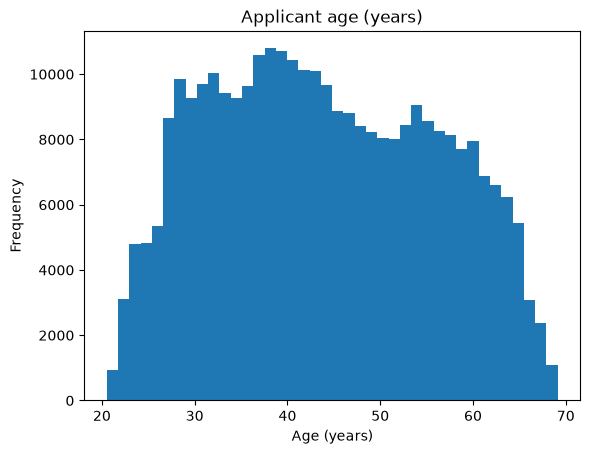

In [ ]:
(df["AGE_YEARS"]
   .plot.hist(bins=40, title="Applicant age (years)", xlabel="Age (years)"));

df.groupby("TARGET")["AGE_YEARS"].mean()

In [ ]:
bands = pd.cut(df["AGE_YEARS"], [20, 30, 40, 50, 60, 70])
df.groupby([bands, "NO_EMPLOYMENT_TENURE"], observed=True)["TARGET"].mean().unstack()

NO_EMPLOYMENT_TENURE,0,1
AGE_YEARS,,
"(20, 30]",0.114493,0.139706
"(30, 40]",0.095702,0.117530
"(40, 50]",0.076273,0.086122
"(50, 60]",0.064905,0.054382
"(60, 70]",0.044159,0.050240


In [ ]:
df.groupby("NO_EMPLOYMENT_TENURE")["AGE_YEARS"].describe()

,count,mean,std,min,25%,50%,75%,max
NO_EMPLOYMENT_TENURE,,,,,,,,
0,252137.0,40.463379,10.034449,20.517808,32.260274,39.926027,48.117808,69.041096
1,55374.0,59.753450,5.501600,21.071233,57.093151,60.413699,63.487671,69.120548


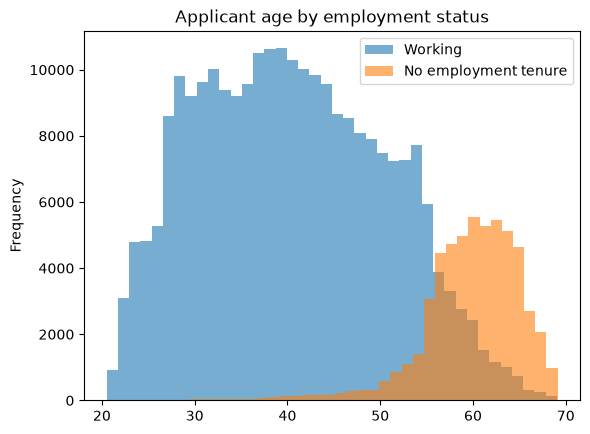

In [ ]:
ax = df[df["NO_EMPLOYMENT_TENURE"] == 0]["AGE_YEARS"].plot.hist(
    bins=40, alpha=0.6, label="Working", xlabel="Age (years)")
df[df["NO_EMPLOYMENT_TENURE"] == 1]["AGE_YEARS"].plot.hist(
    bins=40, alpha=0.6, label="No employment tenure", ax=ax,
    title="Applicant age by employment status")
ax.legend();

In [ ]:
pd.crosstab(pd.cut(df["AGE_YEARS"], range(20, 72, 2)), df["NO_EMPLOYMENT_TENURE"]).assign(
    total=lambda d: d.sum(axis=1))

NO_EMPLOYMENT_TENURE,0,1,total
AGE_YEARS,,,
"(20, 22]",1258,4,1262
"(22, 24]",6968,21,6989
"(24, 26]",8056,26,8082
"(26, 28]",13004,40,13044
"(28, 30]",15599,45,15644
"(30, 32]",16123,65,16188
"(32, 34]",15569,55,15624
"(34, 36]",15347,77,15424
"(36, 38]",17307,114,17421


In [ ]:
bands = pd.cut(df["AGE_YEARS"], [20, 30, 40, 50, 60, 70])
tab = (df.groupby([bands, "NO_EMPLOYMENT_TENURE"], observed=True)["TARGET"]
         .agg(["mean", "size"]).unstack())

w = tab[("size", 0)] / tab[("size", 0)].sum()      # komposisi usia pekerja
standardised = (tab[("mean", 1)] * w).sum()

print(f"mentah          : {df.loc[df.NO_EMPLOYMENT_TENURE==1,'TARGET'].mean():.4f}")
print(f"distandardisasi : {standardised:.4f}")
print(f"pembanding kerja: {df.loc[df.NO_EMPLOYMENT_TENURE==0,'TARGET'].mean():.4f}")

mentah          : 0.0540
distandardisasi : 0.0994
pembanding kerja: 0.0866


In [ ]:
df.loc[(df.NO_EMPLOYMENT_TENURE == 1) & (df.AGE_YEARS < 45),
       ["NAME_INCOME_TYPE", "AGE_YEARS", "TARGET"]].head(20)
df.loc[(df.NO_EMPLOYMENT_TENURE == 1) & (df.AGE_YEARS < 45), "NAME_INCOME_TYPE"].value_counts()

NAME_INCOME_TYPE
Pensioner     1265
Unemployed      11
Name: count, dtype: int64

In [ ]:
df.loc[df.NO_EMPLOYMENT_TENURE == 1].groupby("CODE_GENDER")["AGE_YEARS"].describe()

,count,mean,std,min,25%,50%,75%,max
CODE_GENDER,,,,,,,,
F,45271.0,59.930516,5.032142,21.071233,57.180822,60.263014,63.435616,69.120548
M,10103.0,58.960028,7.187573,22.315068,56.252055,60.964384,63.706849,69.030137


In [ ]:
pd.crosstab(df["CODE_GENDER"], df["NO_EMPLOYMENT_TENURE"], normalize="index")

NO_EMPLOYMENT_TENURE,0,1
CODE_GENDER,,
F,0.776382,0.223618
M,0.903835,0.096165
XNA,1.000000,0.000000


In [ ]:
young_pens = (df.NO_EMPLOYMENT_TENURE == 1) & (df.AGE_YEARS < 45)
young_work = (df.NO_EMPLOYMENT_TENURE == 0) & (df.AGE_YEARS < 45)
print(df.loc[young_pens, "TARGET"].mean(), df.loc[young_work, "TARGET"].mean())

0.11050156739811912 0.09647692592526233


## Key observations

Dataset: `application_train.csv`, 307,511 applications × 122 columns. Target is binary repayment difficulty; base rate 8.07%.

### 1. The class imbalance rules out accuracy as a metric
Only 8.07% of applications are flagged as having repayment difficulty. A model that predicts "no difficulty" for every applicant is 91.93% accurate and catches zero defaults. Model selection will therefore use AUC/Gini and recall at a fixed approval rate, not
accuracy.

### 2. A sentinel value was hiding inside `DAYS_EMPLOYED`, and the column measured
something other than its name
55,374 rows (18.01%) carry the identical value `365243` — approximately 1,000 years of employment, and positive where every genuine `DAYS_*` value is negative. A single impossible value repeated across 18% of rows is a code, not an outlier. It resolves to 55,352 pensioners and 22 unemployed applicants.

Three correlations against `TARGET` show what the raw column was actually measuring:
| variable | corr |
|---|---|
| `DAYS_EMPLOYED`, raw | −0.0449 |
| `NO_EMPLOYMENT_TENURE` (the sentinel flag alone) | −0.0460 |
| `EMPLOYED_YEARS` (sentinel removed) | −0.0750 |

The raw column's predictive power is fully accounted for by the sentinel flag: it was a disguised pensioner indicator, not a measure of job tenure. Once cleaned, genuine tenure is 67% stronger. The sentinel was both contaminating the variable and smuggling a different signal under the wrong name.

Treatment: `365243 → NaN`, plus an explicit `NO_EMPLOYMENT_TENURE` flag so the information is retained rather than discarded.

### 3. Simpson's paradox in employment status — the headline finding
Compared directly, applicants with no employment tenure look substantially safer:
| group | default rate |
|---|---|
| employed | 8.66% |
| no employment tenure | 5.40% |

Reconciliation: 0.180 × 5.40% + 0.820 × 8.66% = 8.07%, the base rate.

Conditioning on age reverses this. The no-tenure group defaults *more* in four of five age
bands:
| age band | employed | no tenure |
|---|---|---|
| (20, 30] | 11.45% | 13.97% |
| (30, 40] | 9.57% | 11.75% |
| (40, 50] | 7.63% | 8.61% |
| (50, 60] | 6.49% | 5.44% |
| (60, 70] | 4.42% | 5.02% |

The aggregate comparison is driven by composition: the no-tenure group has a median age of 60.4 and sits in bands where every group defaults less. Direct standardisation to the employed group's age distribution gives a rate of **9.94%**, against 8.66% for the
employed.

The naive comparison is wrong in direction, not only magnitude: not 37.6% safer but 14.8% riskier. A lender provisioning on the unadjusted 5.40% would understate expected loss on this segment by a factor of 1.84.

A restricted comparison replicates the effect independently: among applicants under 45, the no-tenure group defaults at 11.05% against 9.65% for the employed, a gap of +14.5% against the standardised +14.8%.

Implication: employment status must not enter the model as a main effect alone. It requires an age interaction, and segment-level validation — a global AUC can look healthy while one segment is systematically mispriced.

### 4. `NO_EMPLOYMENT_TENURE` is a partial proxy for gender
P(no employment tenure | female) = 22.36%; P(no employment tenure | male) = 9.62% — women are 2.3× more likely to fall in this group, which is 82% female.

Knowing an applicant has no employment tenure moves the implied probability of being female from roughly 66% to 82%. That is a partial proxy, not a reconstruction, but it demonstrates the central difficulty of fairness work in credit: dropping the protected
attribute does not remove its influence, because individually neutral feature reconstruct it jointly. `CODE_GENDER` will be excluded from the model, and the fitted model tested for disparate impact rather than assumed clean.

An initial hypothesis that the group boundary reflected gender-specific statutory retirement ages was tested and **rejected**: the age distribution of the no-tenure group is near-identical for men (median 60.96) and women (median 60.26). The gender signal travels through composition, not through an age threshold.

### 5. External scores dominate prediction, and the strongest is not the most usable
| feature | corr | coverage |
|---|---|---|
| `EXT_SOURCE_3` | −0.1789 | 80.2% |
| `EXT_SOURCE_2` | −0.1605 | **99.8%** |
| `EXT_SOURCE_1` | −0.1553 | **43.6%** |

All three are normalised scores from external data sources — the bureau analogue here — and they outrank every internal variable by roughly a factor of two. Note that these correlations are computed on different samples, since `corrwith` drops pairs rowwise.

`EXT_SOURCE_2` is the production workhorse: almost as strong as `EXT_SOURCE_3` and available for nearly every applicant. A feature absent at decision time has no value however well it performs in backtest. `EXT_SOURCE_1`, missing for 56% of applicants, cannot carry a scorecard on its own.

Note on magnitude: Pearson correlation against a binary target with 8% prevalence has a low structural ceiling, so 0.18 is a strong relationship here, not a weak one. Feature selection will use IV and univariate Gini rather than Pearson r.

### 6. A third of the dataset describes the building, and it is threefold redundant
47 of 122 columns describe the applicant's dwelling: 14 variables stored as `_AVG`/`_MODE`/`_MEDI` triplets (42 columns) plus 5 categorical `_MODE` fields. The triplets share identical missing rates and near-identical correlations with the target (`FLOORSMAX`: 0.0440 / 0.0438 / 0.0432), confirming they summarise one measurement. Collapsing them reduces 47 columns to 19 variables with no information loss.

These are also the most incomplete columns in the dataset: 41 columns are missing in more than 50% of rows and 17 in more than 60%, almost all from this block (`COMMONAREA_*` at 69.9%).

### 7. Missingness is not random and carries risk signal
Default rate by whether building information is present:

| `COMMONAREA_AVG` | default rate |
|---|---|
| present | 6.91% |
| missing | 8.57% |

A 24% relative difference from a single binary indicator. The causal reading is weak — availability of building data is most plausibly a proxy for housing type or socioeconomic segment — but the information exists at application time, so it is legitimate input. The proxy relationship must be stated in model documentation.

`OWN_CAR_AGE` is a separate case: missing for 100% of applicants reporting no car and for 0.005% of those reporting one. The overall 65.99% missing rate equals the share reporting no car, so the blank means "not applicable", and mean imputation would be false by
construction.

### 8. The sample is already filtered by lending policy
Applicant age runs from 20.5 to 69.1 with abrupt walls at both ends: the (20, 22] band holds 1,262 applicants and (68, 70] holds 874, against a peak of 17,651 at (38, 40]. Only 22 unemployed applicants appear in 307,511 rows. These are policy boundaries, not population demographics.

Everything here therefore describes **accepted** applicants, not applicants in general. Any model trained on this data is silent about those screened out at the gate, which is the reject-inference problem and a stated limitation of anything built from it.
Applicants who default are on average 3.43 years younger (40.78 vs 44.21).

### Open questions
- The employed-group count dips at (50, 52] and rebounds at (52, 54] for reasons not identified here. Possibly a birth-cohort effect; not investigated.
- 1,276 applicants under 45 are flagged as pensioners. Disability pension is the obvious hypothesis but the dataset carries no field confirming it. They default at 11.05% against 9.65% for employed applicants of the same age range.
- `FONDKAPREMONT_MODE` and `WALLSMATERIAL_MODE`